# How the TPR role swap works

Start with a few cached validation tokens, swap the probe's role channels, and check the filler profiles before and after. Then read the completed Qwen3-8B-Base evaluation. The local calculations use the experiment's `native_role_swap` helper on CPU; model scores come from saved inference.

The experiment edits both noun tokens at one layer with α = 1 and unmatched norms. Here the answer score is **patient − agent logit**, and the held-out flip rate is conditional on **baseline agent wins**. The [results notebook](native_tpr_steering_results.ipynb) uses agent − patient logits and bidirectional flips over all sentences, with subgroup filters.


## Load the run

Run from the repository root or `notebook/` in the experiment environment (`/tmp/tpr-binding-gpu-venv/bin/python` here). The plan's checkpoints and cached states must be available. `AC_TPR_NATIVE_RUN` selects another copy of the completed run.

Figures stay inline. Tables and provenance go to `notebook/figures/native_tpr_role_swap/`.


In [1]:
%matplotlib inline
from pathlib import Path
from types import SimpleNamespace
import json
import os
import sys


In [2]:
ROOT = Path.cwd()
if ROOT.name == "notebook":
    ROOT = ROOT.parent
assert (ROOT / "pyproject.toml").is_file(), "Run from the repository root or notebook directory"
run_override = os.environ.get("AC_TPR_NATIVE_RUN")
RUN = (Path(run_override).expanduser().resolve() if run_override else
       ROOT / "ac-tpr-cache/native-tpr-nov6-20261108")
FIGURES = ROOT / "notebook/figures/native_tpr_role_swap"
for folder in [ROOT / "src", ROOT / "scripts/temporary", Path("/tmp/ac-tpr-nov6-extra")]:
    if folder.is_dir() and str(folder) not in sys.path:
        sys.path.insert(0, str(folder))


In [3]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display, Markdown
from run_tpr_nov6 import digest, torch_load
from run_native_tpr_nov6 import load_plan, verify_calibration, read_csv, summarize, ROLES
from native_tpr_interventions import native_role_swap
from diagnose_native_tpr_nov6 import simulate_local_edit, _logits, require_completed_evaluation
from tpr_probe import BilinearTPRProbe

torch.set_num_threads(2)
print("Repository:", ROOT)
print("Run:", RUN)
print("Python:", sys.executable)
print("Device for this notebook: CPU")

print("Current runtime:", {"Python": sys.version.split()[0], "PyTorch": str(torch.__version__)})


/tmp/tpr-binding-gpu-venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Repository: /home/ldomenichelli/Workspace/AC-TPR-native-nov6
Run: /home/ldomenichelli/Workspace/AC-TPR-native-nov6/ac-tpr-cache/native-tpr-nov6-20261108
Python: /tmp/tpr-binding-gpu-venv/bin/python
Device for this notebook: CPU
Current runtime: {'Python': '3.12.3', 'PyTorch': '2.13.0+cu130'}


### Check the inputs

`load_plan` checks the checkpoints, cached states, results, and source hashes. `verify_calibration` checks the run's training-only Soft TPR calibration; the TPR swap itself needs no slot calibration. The saved evaluation must be complete and match the planned layers, methods, and result hash.


In [4]:
declared_plan = json.loads((RUN / "plan.json").read_text())
args = SimpleNamespace(run_dir=RUN, batch_size=declared_plan["batch_size"])
plan, reference = load_plan(args)
verify_calibration(args)
evaluation = require_completed_evaluation(RUN, plan["layers"])
scientific_hashes_before = {name: digest(ROOT / name) for name in plan["source_sha256"]}
assert scientific_hashes_before == plan["source_sha256"]
used_script_hashes_before = {
    name: digest(ROOT / "scripts/temporary" / name)
    for name in ["native_tpr_interventions.py", "diagnose_native_tpr_nov6.py"]
}
run_input_names = ["plan.json", "calibration/metadata.json", "evaluation/metadata.json",
                   "evaluation/results.csv", "diagnostics/metadata.json", "diagnostics/filler_metrics.csv"]
run_hashes_before = {name: digest(RUN / name) for name in run_input_names}


### Run settings


In [5]:
protocol = pd.DataFrame([
    {"Setting": "Model", "Frozen value": plan["model"]},
    {"Setting": "Model revision", "Frozen value": plan["revision"]},
    {"Setting": "Layers", "Frozen value": str(plan["layers"])},
    {"Setting": "Layer selection", "Frozen value": plan["layer_selection"]},
    {"Setting": "Strength", "Frozen value": plan["fixed_alpha"]},
    {"Setting": "Norm matching", "Frozen value": plan["norm_matching"]},
    {"Setting": "Strength selection", "Frozen value": plan["strength_selection"]},
    {"Setting": "Held-out sentences", "Frozen value": evaluation["rows"]},
])
display(protocol)
split_counts = pd.DataFrame([{"Split": split, "Sentences": count}
                             for split, count in plan["expected_counts"].items()])
display(split_counts)

runtime = pd.DataFrame([{"Package": package, "Frozen run version": version}
                        for package, version in plan["runtime"].items()])
display(runtime)


,Setting,Frozen value
0,Model,Qwen/Qwen3-8B-Base
1,Model revision,49e3418fbbbca6ecbdf9608b4d22e5a407081db4
2,Layers,"[20, 21, 22]"
3,Layer selection,"Fixed from historical raw peaks, exploratory; ..."
4,Strength,1.0
5,Norm matching,False
6,Strength selection,none; fixed native alpha=1
7,Held-out sentences,2096


,Split,Sentences
0,gen_test,1680
1,train,3300
2,val,412
3,test,416


,Package,Frozen run version
0,python,3.12.3
1,torch,2.13.0+cu130
2,cuda,13.0
3,transformers,5.9.0
4,nnsight,0.7.0


## What the probe reads

The checkpoint contains the hidden-state center $c$, scalar scale $s$, binding map $M$, learned role matrix $R$, and learned filler matrix $F$. For one token,

$$x=(h-c)/s,\quad Z=\operatorname{reshape}(xM_{\mathrm{flat}}),\quad U=RZ,\quad L=UF^\top.$$

$M_{\mathrm{flat}}$ is the flattened binding map. Each row of $U$ is an unbound role channel; each row of $L$ gives that role's logits over the labeled filler vocabulary.

Training predicts the filler given an annotated role. That tells us what the probe can read, but does not establish that Qwen uses the same representation causally.


### Reading and writing roles

The rows of $R$ read the role channels. When $R$ is invertible, the columns of $R^{-1}$ are the corresponding writing duals. We need those duals to write a change back, rather than just subtracting the two role vectors. The intervention helper checks the required ranks.


In [6]:
source = torch_load(reference / "extraction/states.pt")
assert source["layers"] == plan["layers"]
assert source["states"].dtype == torch.bfloat16
payloads = {layer: torch_load(reference / f"training/layer_{layer}.pt")
            for layer in plan["layers"]}
shape_rows = []
for layer, payload in payloads.items():
    for name in ["M", "R", "F"]:
        shape_rows.append({"Layer": layer, "Parameter": name,
                           "Actual checkpoint shape": str(tuple(payload["state_dict"][name].shape))})
parameter_shapes = pd.DataFrame(shape_rows)
display(parameter_shapes)
print("Original filler vocabulary:", ", ".join(payloads[plan["layers"][0]]["fillers"]))
print("Cached state shape [sentence, layer, role token, hidden]:", tuple(source["states"].shape))


,Layer,Parameter,Actual checkpoint shape
0,20,M,"(4096, 2, 8)"
1,20,R,"(2, 2)"
2,20,F,"(19, 8)"
3,21,M,"(4096, 2, 8)"
4,21,R,"(2, 2)"
5,21,F,"(19, 8)"
6,22,M,"(4096, 2, 8)"
7,22,R,"(2, 2)"
8,22,F,"(19, 8)"


Original filler vocabulary: Anna, David, Emma, James, John, Lisa, Peter, Sarah, Tom, ball, box, branch, car, chef, doctor, door, driver, farmer, pilot
Cached state shape [sentence, layer, role token, hidden]: (5808, 3, 2, 4096)


## Write the swap back to the hidden state

Let $P$ exchange the two role channels. The helper computes

$$\Delta Z=R^{-1}(P-I)RZ,\qquad
\Delta h=s\,\operatorname{vec}(\Delta Z)M_{\mathrm{flat}}^{+}.$$

The pseudoinverse gives the smallest Euclidean hidden-state change that realizes $\Delta Z$, provided the binding map has full column rank. The component in the binding map's nullspace stays unchanged; the helper already accounts for centering.

At α = 1, the ideal target is $U'=PU$ and $L'=PL$: exchange the whole filler-logit profiles, including the non-winning fillers. Rescaling or norm matching would generally change that target.


### What the local check measures

Float32 construction and BF16 rounding introduce numerical error. We can measure that error on the cached source states. In the GPU run, directions computed from those baseline states were added at the live hook; the local checks below do not capture the live post-edit activations.


## Try a few validation tokens

Take the first two validation sentences per voice in cache order, without selecting on outcomes. Labels identify the examples; the steering helper receives only the checkpoint and hidden states.


In [7]:
example_ids = []
for voice in ["active", "passive"]:
    voice_ids = [i for i, row in enumerate(source["rows"])
                 if row["split"] == "val" and row["voice"] == voice]
    assert len(voice_ids) >= 2
    example_ids.extend(voice_ids[:2])
example_rows = [source["rows"][i] for i in example_ids]
assert all(row["split"] == "val" for row in example_rows)
examples = pd.DataFrame([
    {"Cache row ID": i, "Quad ID": row["quad_id"], "Split": row["split"],
     "Voice": row["voice"], "Sentence": row["sentence"],
     "Agent filler": row["agent"], "Patient filler": row["patient"]}
    for i, row in zip(example_ids, example_rows)
])
display(examples)
token_rows = [
    {"Cache row ID": i, "Voice": row["voice"], "Source role": role,
     "Target readout role": ROLES[1 - role_index], "Gold filler": row[role]}
    for i, row in zip(example_ids, example_rows)
    for role_index, role in enumerate(ROLES)
]


,Cache row ID,Quad ID,Split,Voice,Sentence,Agent filler,Patient filler
0,48,12,val,active,John kicked Peter.,John,Peter
1,50,12,val,active,Peter kicked John.,Peter,John
2,49,12,val,passive,Peter was kicked by John.,John,Peter
3,51,12,val,passive,John was kicked by Peter.,Peter,John


In [8]:
local_examples = {}
local_metrics = []
readout_rows = []
for layer_index, layer in enumerate(plan["layers"]):
    payload = payloads[layer]
    h = source["states"][example_ids, layer_index].float().flatten(0, 1)
    # The steering operation is the exact helper used by the saved experiment.
    delta, checks = native_role_swap(payload, h)
    after = simulate_local_edit(h, delta)
    with torch.random.fork_rng(devices=[]):
        probe = BilinearTPRProbe(**payload["config"])
    probe.load_state_dict(payload["state_dict"])
    probe.eval().requires_grad_(False)
    before_logits = _logits(probe, payload, h)
    after_logits = _logits(probe, payload, after)
    local_examples[layer] = dict(h=h, delta=delta, before=before_logits,
                                 after=after_logits, checks=checks)
    local_metrics.append({
        "Layer": layer, "Tokens": checks["tokens"],
        "Binding rank": checks["binding_rank"], "Role rank": checks["role_rank"],
        "Mean native edit norm": checks["delta_norm_mean"],
        "Float32 profile relative error": checks["float32_logit_swap_relative_error"],
        "BF16 profile relative error": checks["bfloat16_logit_swap_relative_error"],
        "Exactly zero token edits": checks["zero_delta_tokens"],
    })
    for token_index, token in enumerate(token_rows):
        source_role = ROLES.index(token["Source role"])
        before_id = int(before_logits[token_index, source_role].argmax())
        after_id = int(after_logits[token_index, 1 - source_role].argmax())
        readout_rows.append({
            "Layer": layer, **token,
            "Known to probe": token["Gold filler"] in payload["fillers"],
            "Before: source-role prediction": payload["fillers"][before_id],
            "After BF16: target-role prediction": payload["fillers"][after_id],
            "Native edit norm": float(delta[token_index].double().norm()),
        })


### Numerical error and token readouts


In [9]:
local_statistics = pd.DataFrame(local_metrics)
display(local_statistics)
# Show the first frozen layer's token readouts; all layers were computed above.
readouts = pd.DataFrame(readout_rows)
display(readouts[readouts["Layer"] == plan["layers"][0]])


,Layer,Tokens,Binding rank,Role rank,Mean native edit norm,Float32 profile relative error,BF16 profile relative error,Exactly zero token edits
0,20,8,16,2,29.453183,1.164954e-08,0.000720,0
1,21,8,16,2,37.225376,6.892990e-09,0.000521,0
2,22,8,16,2,43.652462,8.576909e-09,0.000542,0


,Layer,Cache row ID,Voice,Source role,Target readout role,Gold filler,Known to probe,Before: source-role prediction,After BF16: target-role prediction,Native edit norm
0,20,48,active,agent,patient,John,True,John,John,25.923290
1,20,48,active,patient,agent,Peter,True,Peter,Peter,32.689982
2,20,50,active,agent,patient,Peter,True,Peter,Peter,17.386291
3,20,50,active,patient,agent,John,True,John,John,34.420389
4,20,49,passive,agent,patient,John,True,John,John,32.938171
5,20,49,passive,patient,agent,Peter,True,Peter,Peter,23.159690
6,20,51,passive,agent,patient,Peter,True,Peter,Peter,36.032987
7,20,51,passive,patient,agent,John,True,John,John,33.074662


## Compare the filler profiles

For one validation token, compare each original role channel with the opposite channel after the BF16 edit. Agreement means we reached the probe's swap target; it does not by itself imply a changed Qwen answer.

Profile errors use the helper's float64 calculation with float32 checkpoint parameters. The state precision is labeled as float32 or BF16. Predictions use the float32 probe and the same `simulate_local_edit` and `_logits` functions as the saved diagnostics.


In [10]:
plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#94a3b8",
    "axes.labelcolor": "#334155",
    "xtick.color": "#475569",
    "ytick.color": "#475569",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "figure.dpi": 130,
})
COLORS = {"before": "#0072B2", "after": "#D55E00"}
FIGURES.mkdir(parents=True, exist_ok=True)


def show_figure(fig):
    """Display the figure inline and release its plotting resources."""
    plt.show()
    plt.close(fig)


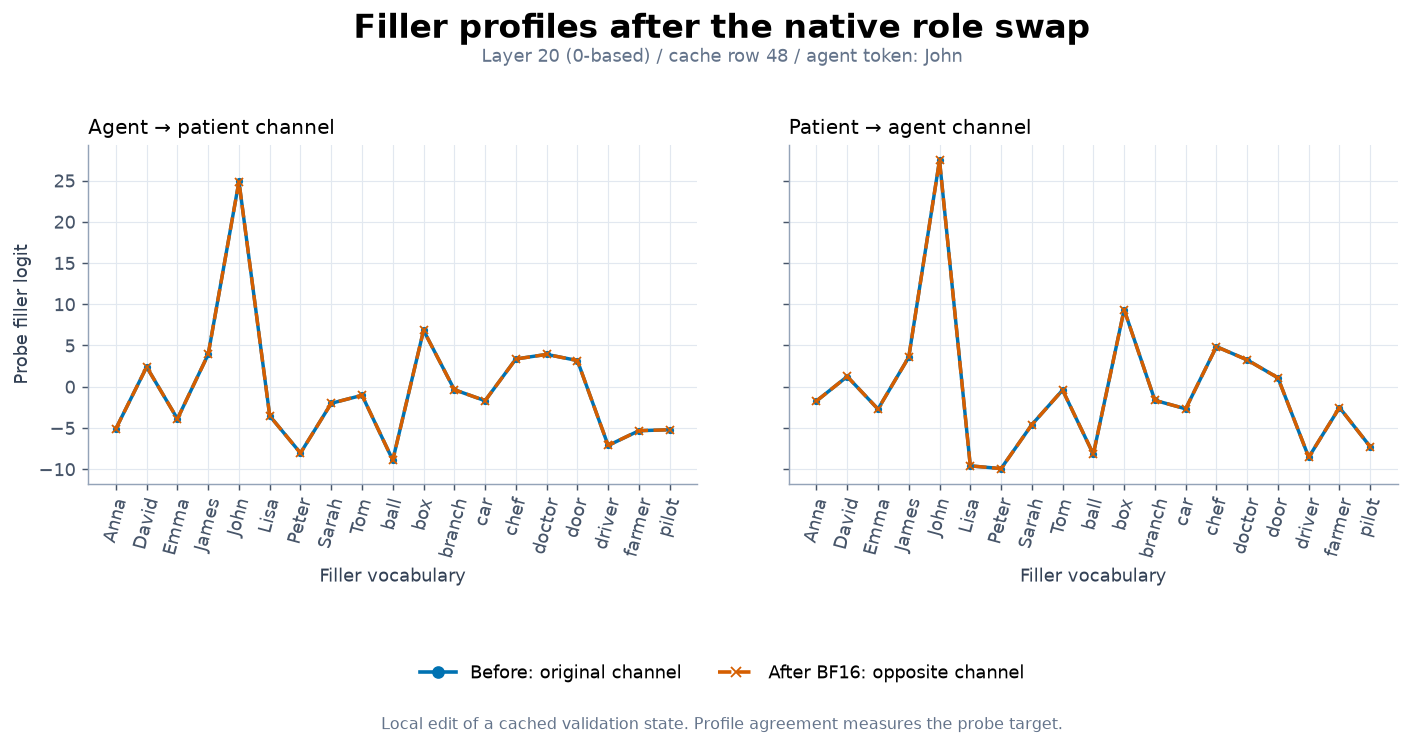

In [11]:
example_layer = plan["layers"][0]
example_token = 0
example = local_examples[example_layer]
filler_names = payloads[example_layer]["fillers"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5.8), sharey=True)
for role_index, ax in enumerate(axes):
    ax.plot(filler_names, example["before"][example_token, role_index].tolist(),
            color=COLORS["before"], linewidth=1.9, marker="o", markersize=3)
    ax.plot(filler_names, example["after"][example_token, 1 - role_index].tolist(),
            color=COLORS["after"], linewidth=1.9, linestyle="--", marker="x", markersize=4)
    ax.set_title(f"{ROLES[role_index].capitalize()} → {ROLES[1 - role_index]} channel", loc="left")
    ax.set_xlabel("Filler vocabulary")
    ax.tick_params(axis="x", rotation=75)
    ax.grid(color="#e2e8f0", linewidth=0.65)
    ax.set_axisbelow(True)
axes[0].set_ylabel("Probe filler logit")
fig.suptitle("Filler profiles after the native role swap", fontsize=18, weight="bold", y=0.985)
fig.text(0.5, 0.92,
         f"Layer {example_layer} (0-based) / cache row {token_rows[example_token]['Cache row ID']} / "
         f"{token_rows[example_token]['Source role']} token: {token_rows[example_token]['Gold filler']}",
         ha="center", color="#64748b", fontsize=10)
handles = [
    Line2D([0], [0], color=COLORS["before"], linewidth=2, marker="o", label="Before: original channel"),
    Line2D([0], [0], color=COLORS["after"], linewidth=2, linestyle="--", marker="x",
           label="After BF16: opposite channel"),
]
fig.legend(handles=handles, loc="lower center", bbox_to_anchor=(0.5, 0.075), ncol=2, frameon=False)
fig.text(0.5, 0.035, "Local edit of a cached validation state. Profile agreement measures the probe target.",
         ha="center", color="#64748b", fontsize=9)
fig.subplots_adjust(top=0.81, bottom=0.36, wspace=0.15)
show_figure(fig)


## What happens to the model answers?

`summarize` recomputes the saved Qwen summary. Positive **patient − agent** logits favor the patient. A conditional flip has a strictly negative baseline score and a strictly positive edited score; divide by **baseline agent wins**. Ties are neither wins nor flips.

These are answer-token preferences after editing both nouns together at α = 1, not free-form generations. The [results notebook](native_tpr_steering_results.ipynb) adds subgroup plots and bidirectional flips over all sentences.


In [12]:
METHOD = "tpr_native_role_swap"
saved_records = read_csv(RUN / "evaluation/results.csv")
assert len(saved_records) == evaluation["result_rows"]
method_records = [row for row in saved_records if row["method"] == METHOD]
assert len(method_records) == evaluation["rows"] * len(plan["layers"])
assert all(float(row["alpha"]) == plan["fixed_alpha"] for row in method_records)
summary = pd.DataFrame(summarize(method_records))
heldout_display = summary[["split", "voice", "layer", "sentences", "baseline_agent_wins", "flips",
                           "conditional_flip", "mean_margin_change", "mean_agent_edit_norm",
                           "mean_patient_edit_norm"]].copy()
heldout_display["conditional_flip"] *= 100
heldout_display.columns = ["Split", "Voice", "Layer", "Sentences", "Eligible baseline agent wins", "Flips",
                           "Conditional flip (%)", "Mean margin change", "Mean agent edit norm",
                           "Mean patient edit norm"]
display(heldout_display)
display(Markdown("Result provenance: " + ", ".join(
    f"`{origin}`: {count} rows" for origin, count in
    pd.Series([row["result_origin"] for row in method_records]).value_counts().items())))


,Split,Voice,Layer,Sentences,Eligible baseline agent wins,Flips,Conditional flip (%),Mean margin change,Mean agent edit norm,Mean patient edit norm
0,gen_test,active,20,840,840,0,0.000000,0.383780,26.826733,29.101643
1,gen_test,active,21,840,840,0,0.000000,0.517857,30.654195,32.782615
2,gen_test,active,22,840,840,0,0.000000,0.547470,36.118639,41.552350
3,gen_test,passive,20,840,839,0,0.000000,1.817708,34.365373,29.554261
4,gen_test,passive,21,840,839,0,0.000000,1.424107,40.712555,40.464958
5,gen_test,passive,22,840,839,0,0.000000,1.401637,45.618736,44.322154
6,test,active,20,208,208,0,0.000000,0.253005,29.374204,32.053697
7,test,active,21,208,208,0,0.000000,0.354567,34.989883,37.602307
8,test,active,22,208,208,0,0.000000,0.396635,42.321374,45.289583
9,test,passive,20,208,208,1,0.480769,1.576923,35.390553,33.451592


Result provenance: `scored`: 6288 rows

## Can the probe still read the filler?

The saved table gives gold-filler accuracy by voice and source role for tokens in the probe vocabulary. Read the source role before editing and the opposite role afterward. Counts show the denominator.

These are BF16 simulations on cached states, not live Qwen activations. Out-of-vocabulary fillers are excluded: a stable predicted vocabulary label would not establish their identity.


In [13]:
diagnostic_metadata = json.loads((RUN / "diagnostics/metadata.json").read_text())
assert diagnostic_metadata["status"] == "complete"
for name, expected in diagnostic_metadata["input_sha256"].items():
    assert digest(RUN / name) == expected, name
filler_path = RUN / "diagnostics/filler_metrics.csv"
assert digest(filler_path) == diagnostic_metadata["files_sha256"][filler_path.name]
filler_metrics = pd.read_csv(filler_path)
known = filler_metrics[(filler_metrics["method"] == METHOD) &
                       (filler_metrics["vocabulary"] == "known")].copy()
known = known.sort_values(["split", "voice", "layer", "source_role"])
filler_display = known[["split", "voice", "layer", "source_role", "known_tokens",
                        "filler_before_correct", "filler_after_target_correct",
                        "filler_before_accuracy", "filler_after_target_accuracy",
                        "native_ideal_logits_relative_error"]].copy()
filler_display[["filler_before_accuracy", "filler_after_target_accuracy"]] *= 100
filler_display.columns = ["Split", "Voice", "Layer", "Source role", "Known tokens",
                          "Correct before", "Correct after at target role", "Before accuracy (%)",
                          "After accuracy (%)", "BF16 profile relative error"]
display(filler_display)


,Split,Voice,Layer,Source role,Known tokens,Correct before,Correct after at target role,Before accuracy (%),After accuracy (%),BF16 profile relative error
21,gen_test,active,20,agent,396,396,396,100.0,100.0,0.000501
24,gen_test,active,20,patient,396,396,396,100.0,100.0,0.000501
81,gen_test,active,21,agent,396,396,396,100.0,100.0,0.000388
84,gen_test,active,21,patient,396,396,396,100.0,100.0,0.000451
141,gen_test,active,22,agent,396,396,396,100.0,100.0,0.000376
144,gen_test,active,22,patient,396,396,396,100.0,100.0,0.000418
27,gen_test,passive,20,agent,396,396,396,100.0,100.0,0.000522
30,gen_test,passive,20,patient,396,396,396,100.0,100.0,0.000431
87,gen_test,passive,21,agent,396,396,396,100.0,100.0,0.000428
90,gen_test,passive,21,patient,396,396,396,100.0,100.0,0.000413


## Save the tables

Save all validation readouts, the displayed tables, and their input hashes. Recheck the scientific sources, calibration, and run artifacts before writing the exports. Figures stay inline.


In [14]:
assert {name: digest(ROOT / name) for name in plan["source_sha256"]} == scientific_hashes_before
assert {name: digest(ROOT / "scripts/temporary" / name) for name in used_script_hashes_before} == used_script_hashes_before
assert {name: digest(RUN / name) for name in run_input_names} == run_hashes_before
verify_calibration(args)
print("Verified: frozen scientific sources, imported diagnostic helper, calibration, and inspected run artifacts are unchanged.")
print("Steering was reexecuted only through the original native_role_swap helper on real validation states.")


Verified: frozen scientific sources, imported diagnostic helper, calibration, and inspected run artifacts are unchanged.
Steering was reexecuted only through the original native_role_swap helper on real validation states.


In [15]:
for name, table in {
    "protocol": protocol,
    "split_counts": split_counts,
    "runtime": runtime,
    "parameter_shapes": parameter_shapes,
    "validation_examples": examples,
    "local_statistics": local_statistics,
    "validation_readouts": readouts,
    "heldout_summary": heldout_display,
    "heldout_filler_statistics": filler_display,
}.items():
    table.to_csv(FIGURES / f"{name}.csv", index=False)


In [16]:
provenance = {
    "run_directory": str(RUN.resolve()),
    "model": plan["model"],
    "model_revision": plan["revision"],
    "method": METHOD,
    "layers": plan["layers"],
    "alpha": plan["fixed_alpha"],
    "norm_matching": plan["norm_matching"],
    "validation_example_ids": example_ids,
    "plot_example": {"layer": example_layer, "token_index": example_token},
    "scientific_source_sha256": scientific_hashes_before,
    "imported_helper_sha256": used_script_hashes_before,
    "run_input_sha256": run_hashes_before,
    "answer_score": "patient answer-token logit minus agent answer-token logit",
    "conditional_flip_rate": "strict agent-to-patient flips / baseline agent wins",
    "ties": "Ties count as neither wins nor flips",
    "local_edit": "BF16(h.float() + delta).float() on cached validation states",
    "uncertainty": "Descriptive tables and profiles; no uncertainty intervals",
}
(FIGURES / "plot_metadata.json").write_text(json.dumps(provenance, indent=2) + "\n")
print(f"Tables and provenance saved to {FIGURES}")


Tables and provenance saved to /home/ldomenichelli/Workspace/AC-TPR-native-nov6/notebook/figures/native_tpr_role_swap


## Reading the results

The local check asks whether the edit reaches the probe target. The held-out scores ask whether Qwen's answer changes. Read both alongside the filler diagnostics, keeping their different units and denominators in mind.

α = 1 keeps the native swap target, but does not match edit norms across methods. The three historically selected layers remain exploratory. Continue with the [Soft TPR walkthrough](native_soft_tpr_slot_swap.ipynb) or [comparative results](native_tpr_steering_results.ipynb).
